In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.ticker import FuncFormatter

In [2]:
url = "https://raw.githubusercontent.com/FloreGab/datavisual/main/N1_Avg_vs_affordable-studio_wage/Avg_vs_affordable-studio_wage.xlsx"
df = pd.read_excel(url)
df = df.sort_values("Difference", ascending = True).reset_index(drop = True)

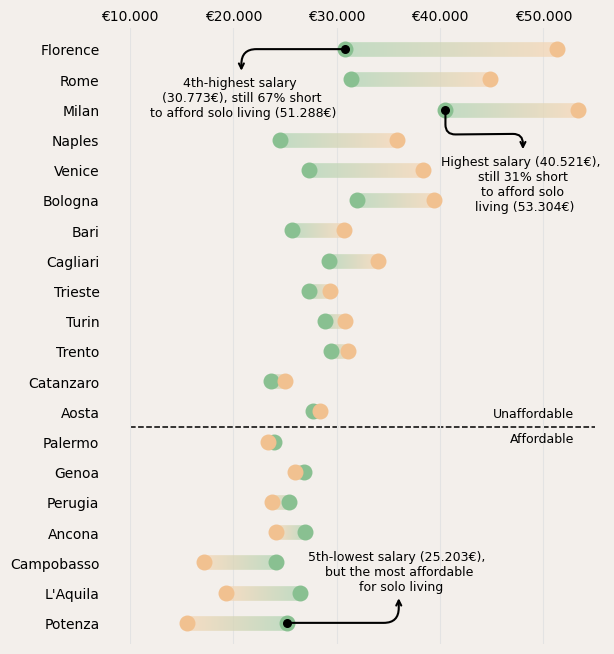

In [3]:
col_wage, col_min = "#89c091", "#f1c190"

def lighten(color, amount=0.65):
    return tuple(amount * c + (1 - amount) for c in to_rgb(color))
    
cmap = LinearSegmentedColormap.from_list("grad", [lighten(col_wage), lighten(col_min)])

dot_size = 110
band_width = np.sqrt(dot_size)

fig, ax = plt.subplots(figsize = (6,8))

fig.patch.set_facecolor('#f3efeb') 
ax.set_facecolor('#f3efeb')        

y = range(len(df))

N = 1000
t = np.linspace(0, 1, N + 1)
segments, values = [], []
for i, row in df.iterrows():
    xs = row["Avg_Wage"] + t * (row["Min_Affordable_wage_60Mq"] - row["Avg_Wage"])
    pts = np.column_stack([xs, np.full(N + 1, i)])
    segments.extend(np.stack([pts[:-1], pts[1:]], axis=1))
    values.extend(t[:-1])

lc = LineCollection(segments, cmap=cmap, linewidths=band_width, capstyle="butt", zorder=1)
lc.set_array(np.array(values))
ax.add_collection(lc)

ax.scatter(df["Avg_Wage"], y, color=col_wage, s=dot_size, zorder=2, label="Average salary")
ax.scatter(df["Min_Affordable_wage_60Mq"], y, color=col_min, s=dot_size, zorder=2, label="Affordable salary \n for two-room flat")

ax.set_yticks(list(y)); ax.set_yticklabels(df["City"])

ax.set_xticks(range(10000, 60000, 10000))

ax.xaxis.tick_top()

ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"€{v:,.0f}".replace(",", ".")))
ax.set_xlim(10000, 55000); ax.set_ylim(-0.7, len(df) - 0.3)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="both", length=0)
ax.tick_params(axis="y", pad=22)

ax.set_axisbelow(True)
ax.grid(axis="x", color="#E3E3E3", linewidth=0.8)

target_name1 = "Milan"
if target_name1 in df["City"].values:
    milano_row = df[df["City"] == target_name1].iloc[0]
    milano_idx = df.index[df["City"] == target_name1].tolist()[0]
    
    milano_min_wage = milano_row["Avg_Wage"]
    
    testo_milano = "Highest salary (40.521€), \n still 31% short \n to afford solo \n living (53.304€)"
    
    ax.scatter(milano_min_wage, milano_idx, color="black", s=30, zorder=4)
    
    ax.annotate(testo_milano,
                xy=(milano_min_wage, milano_idx),                
                xytext=(milano_min_wage + 7500, milano_idx - 1.5), 
                ha="center", va="top", fontsize=9,
                arrowprops=dict(
                    arrowstyle="<-",
                    color="black",
                    lw=1.5,
                    connectionstyle="arc,angleA=90,angleB=-90,armA=50,armB=25,rad=10"
                ))

target_name2 = "Potenza"
if target_name2 in df["City"].values:
    potenza_row = df[df["City"] == target_name2].iloc[0]
    potenza_idx = df.index[df["City"] == target_name2].tolist()[0]
    
    potenza_avg_wage = potenza_row["Avg_Wage"]
    
    testo_potenza = "5th-lowest salary (25.203€), \n but the most affordable \n for solo living"
    
    ax.scatter(potenza_avg_wage, potenza_idx, color="black", s=30, zorder=4)
    
    ax.annotate(testo_potenza,
                xy=(potenza_avg_wage, potenza_idx),                  
                xytext=(potenza_avg_wage + 10800, potenza_idx + 1), 
                ha="center", va="bottom", fontsize=9,
                arrowprops=dict(
                    arrowstyle="<-",                     
                    color="black",
                    lw=1.5,
                    connectionstyle="angle,angleA=90,angleB=0,rad=15"
                ))

target_name2 = "Florence"
if target_name2 in df["City"].values:
    firenze_row = df[df["City"] == target_name2].iloc[0]
    firenze_idx = df.index[df["City"] == target_name2].tolist()[0]
    
    firenze_avg_wage = firenze_row["Avg_Wage"]
    
    testo_firenze = "4th-highest salary \n (30.773€), still 67% short \n to afford solo living (51.288€)"
    
    ax.scatter(firenze_avg_wage, firenze_idx, color="black", s=30, zorder=4)
    
    ax.annotate(testo_firenze,
                xy=(firenze_avg_wage, firenze_idx),                  
                # firenze_idx + 0.8 sposta il testo visivamente in basso (verso Roma)
                xytext=(firenze_avg_wage - 10000, firenze_idx - 0.9), 
                ha="center", va="top", fontsize=9, # ha="right" allinea il testo a sinistra della punta
                arrowprops=dict(
                    arrowstyle="<-",                      
                    color="black",
                    lw=1.5,
                    connectionstyle="angle,angleA=90,angleB=0,rad=15"
                ))

if "Aosta" in df["City"].values and "Palermo" in df["City"].values:
    aosta_idx = df.index[df["City"] == "Aosta"].tolist()[0]
    palermo_idx = df.index[df["City"] == "Palermo"].tolist()[0]
    
    mid_y = (aosta_idx + palermo_idx) / 2

    ax.axhline(mid_y, xmin=0, xmax=1, color="black", linestyle="--", linewidth=1.1, zorder=0)
    

    ax.text(53000, mid_y - 0.2, "Affordable", color="black", fontsize=9, va="top", ha="right")
    ax.text(53000, mid_y + 0.2, "Unaffordable", color="black", fontsize=9, va="bottom", ha="right")

plt.show()